In [1]:
import pandas as pd 
import numpy as np 
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)
pd.set_option('max_colwidth', -1)

C:\Users\C5364375\AppData\Local\Temp\ipykernel_38136\4157310711.py:6: FutureWarning: Passing a negative integer is deprecated in version 1.0 and will not be supported in future version. Instead, use None to not limit the column width.
  pd.set_option('max_colwidth', -1)


In [2]:
KNAB_donations_raw = pd.read_excel("20240125_KNAB_donations.xlsx")
# Data Source: Data Scrapped from website by Latvia OpenData Team https://info.knab.gov.lv/lv/db/ziedojumi/ 

In [3]:
beneficial_owners_raw = pd.read_csv("beneficial_owners.csv", delimiter=';')
# Data Source: https://data.gov.lv/dati/eng/dataset/patiesie-labuma-guveji/resource/20a9b26d-d056-4dbb-ae18-9ff23c87bdee

In [76]:
pdb_sloregistrs_odata_raw = pd.read_csv("pdb_sloregistrs_odata.csv")
# Data Source: https://data.gov.lv/dati/eng/dataset/sabiedriska-labuma-organizacijas/resource/476c04af-877c-4136-adc1-a42841650e45
# EU country Rules of Public benefits Organisation https://www.europarl.europa.eu/RegData/etudes/STUD/2023/753422/IPOL_STU(2023)753422_EN.pdf 

In [5]:
nodes_officers = pd.read_csv("nodes-officers.csv")
# Whistel Blowers panama papaers data aggregated
nodes_officers['name'] = nodes_officers['name'].replace(['Miss ','Mr\. ','Mrs\. ', 'Ms\. '],'', regex=True)
nodes_officers['name_leak'] = nodes_officers['name']

In [6]:
pdb_sloregistrs_odata_raw.columns = ['Name of organization', 'Registration code', 'Type of organization', 
                                       'Status', 'Address', 'Effective from', 'Effective until', 
                                       'Date of decision', 'Decision number', 'Substance of decision ', 
                                       'Effective date of the decision', 'Name of scope', 
                                       'Effective date of scope']

In [7]:
public_benefit_organisations = pdb_sloregistrs_odata_raw[['Registration code', 'Type of organization', 'Status','Name of scope']]

In [9]:
beneficial_owners = beneficial_owners_raw.copy()
KNAB_donations = KNAB_donations_raw.copy()
public_benefit_organisations_df = public_benefit_organisations.copy()

In [10]:
import difflib
from dataclasses import dataclass

import pandas as pd



@dataclass()
class FuzzyMerge:
    """
        Works like pandas merge except also merges on approximate matches.
    """
    left: pd.DataFrame
    right: pd.DataFrame
    left_on: str
    right_on: str
    how: str = "inner"
    cutoff: float = 0.3

    def main(self) -> pd.DataFrame:
        temp = self.right.copy()
        temp[self.left_on] = [
            self.get_closest_match(x, self.left[self.left_on]) for x in temp[self.right_on]
                            ]

        return self.left.merge(temp, on=self.left_on, how=self.how)

    def get_closest_match(self, left: pd.Series, right: pd.Series) -> str or None:
        matches = difflib.get_close_matches(left, right, cutoff=self.cutoff)

        return matches[0] if matches else None
    
def list_of_values(x):
    return list(x)

In [11]:
beneficial_owners['PrimaryKey'] = beneficial_owners['forename'] + " " + beneficial_owners['surname'] +  beneficial_owners['latvian_identity_number_masked']
beneficial_owners['PrimaryKey'] = beneficial_owners['PrimaryKey'].str.replace(r'\W', '', regex=True)

beneficial_owners_df_agg = beneficial_owners.groupby('PrimaryKey').agg(
                                    count=('legal_entity_registration_number', 'count'),
                                    values_list=('legal_entity_registration_number', list_of_values)).reset_index()
beneficial_owners_df_agg.columns = ['PrimaryKey', 'NumberOfLegalEntities', 'legal_entity_registration_number']
beneficial_owners_df_agg


,PrimaryKey,NumberOfLegalEntities,legal_entity_registration_number
0,AarnoTapaniJaakola050453,2,"[40103959346, 40103311325]"
1,AaronTimothyDavidMcelroy321112,1,[40203159453]
2,AbaGercbahs240761,1,[40008052693]
3,AbbosGulomov327835,2,"[40003831194, 40203414583]"
4,AbdeldjalilHamar030789,1,[40203322062]
...,...,...,...
133537,ŽerārsĶeružis170866,1,[42101017263]
133538,ŽerārsŠulcs180668,1,[43603077287]
133539,ŽeņaAgamaļijeva040460,1,[40203046405]
133540,ŽivileAdomaitite230383,8,"[44103131909, 40203085559, 40003835660, 40003526415, 40003807722, 40003661337, 40003774243, 50203527491]"


In [78]:
beneficial_owners_df_agg[beneficial_owners_df_agg['NumberOfLegalEntities']>3]

,PrimaryKey,NumberOfLegalEntities,legal_entity_registration_number,name,best_match
PrimaryKey,,,,,
AdilbeksŽanabajevs,AdilbeksŽanabajevs040764,7,"[40103976242, 40003631525, 40003647009, 52103108431, 40003861339, 40203210876, 40103447323]",AdilbeksŽanabajevs,"(ALEKSANDRSBRANDAVS, 61, 709352)"
AdrianoCarlesi,AdrianoCarlesi050655,4,"[40203098591, 40103908848, 40008303366, 40103818934]",AdrianoCarlesi,"(ARNISANCUPANS, 59, 706838)"
AelitaSaulīte,AelitaSaulīte210348,8,"[40103979728, 40103760860, 40103746814, 40103746994, 40103755272, 40103970343, 40103992389, 40103847238]",AelitaSaulīte,"(ANITABALODE, 58, 640695)"
AgitaEglinska,AgitaEglinska310370,7,"[53603090041, 40008295656, 43603056285, 40008316500, 40203521482, 40008233891, 40008326123]",AgitaEglinska,"(AgitaCEIKO, 70, 696342)"
AgitaKausa,AgitaKausa220269,6,"[40003996990, 40103232097, 40203070515, 40103652932, 40103758993, 40103160634]",AgitaKausa,"(AgitaCEIKO, 60, 696342)"
...,...,...,...,...,...
ŪdoOga,ŪdoOga121072,4,"[50203030181, 40203397423, 40003129189, 48503011617]",ŪdoOga,"(DACEGEVORGYAN, 42, 747530)"
ŽannaDragune,ŽannaDragune310583,4,"[40203221117, 40103939547, 40203321777, 40103734406]",ŽannaDragune,"(SantaMORKANE, 58, 766916)"
ŽannaPahomova,ŽannaPahomova140683,4,"[50003481511, 40003982793, 40203049844, 40003687196]",ŽannaPahomova,"(ANDASTEPANOVICA, 57, 747242)"


In [13]:
KNAB_donations['PrimaryKey'] = KNAB_donations['donor'].str.replace(r'\W', '', regex=True)


In [14]:
KNAB_donations_agg = KNAB_donations.groupby(['PrimaryKey']).agg({'donation_EUR':['sum', 'count'], 
                                                                 'person_name_surname':['first'],
                                                                 'party_regnum':['nunique']}).reset_index()

KNAB_donations_agg.columns = KNAB_donations_agg.columns.get_level_values(0)
KNAB_donations_agg.columns = ['PrimaryKey', 'Total_donation_EUR', 'times_donated', 'person_name_surname', 'Unique_parties_donated']

In [15]:

businessOwnersWhoDonateToPoliticalParties = KNAB_donations_agg.merge(beneficial_owners_df_agg, on='PrimaryKey', how='inner')


In [16]:
businessOwnersWhoDonateToPoliticalParties

,PrimaryKey,Total_donation_EUR,times_donated,person_name_surname,Unique_parties_donated,NumberOfLegalEntities,legal_entity_registration_number
0,AdelinaMareida050777,100.00,1,Adelina Mareida,1,2,"[40103195848, 40103299728]"
1,AdrijaKeiša291162,4451.50,9,Adrija Keiša,2,2,"[40203115139, 40103298101]"
2,AelitaPogule200663,439.79,1,Aelita Pogule,1,2,"[40003893739, 40003328448]"
3,AelitaSaulīte210348,1000.00,1,Aelita Saulīte,1,8,"[40103979728, 40103760860, 40103746814, 40103746994, 40103755272, 40103970343, 40103992389, 40103847238]"
4,AgitaDaukste050286,3500.00,1,Agita Daukste,1,1,[40203163321]
...,...,...,...,...,...,...,...
3451,ŪvePerlbahs131170,500.00,2,Ūve Perlbahs,1,1,[40003505127]
3452,ŽaneteEglīte170583,2190.00,8,Žanete Eglīte,2,2,"[40203141381, 40203049933]"
3453,ŽanisJarinovskis210102,17.00,6,Žanis Jarinovskis,1,1,[40008239023]
3454,ŽannaKareļina040379,12994.96,15,Žanna Kareļina,1,1,[50003562511]


In [17]:
cond1 = businessOwnersWhoDonateToPoliticalParties['Unique_parties_donated'] >2
cond2 = businessOwnersWhoDonateToPoliticalParties['Total_donation_EUR'] >10000
cond3 = businessOwnersWhoDonateToPoliticalParties['NumberOfLegalEntities'] >2

### Beneficial Business Individuals who have donated to more than 2 political parties and it's more than 10K EUR

In [18]:
businessOwnersWhoDonateToPoliticalParties[cond1 & cond2]

,PrimaryKey,Total_donation_EUR,times_donated,person_name_surname,Unique_parties_donated,NumberOfLegalEntities,legal_entity_registration_number
144,AivarsLembergs260953,35110.00,12,Aivars Lembergs,4,15,"[40003100234, 40003236622, 50003242141, 40003308583, 41203037098, 41203000150, 41203019961, 40103554896, 41203064700, 40003139990, 50003179321, 40003308507, 40003136693, 41203009997, 41203046226]"
430,AndrisRubins191147,26685.01,44,Andris Rubins,3,3,"[40008043296, 40103275895, 40008305795]"
432,AndrisSkride220482,26375.32,34,Andris Skride,3,3,"[40008212705, 40008246646, 40203478620]"
512,ArgodsLūsiņš090859,35000.00,6,Argods Lūsiņš,3,15,"[40003229495, 48501007424, 40203199437, 40003755825, 40003490368, 58503002391, 40003583329, 41203029654, 40003657967, 40003403267, 40103490966, 40003839145, 40203080123, 40203080119, 40003010405]"
598,ArtisPabriks220366,63498.00,30,Artis Pabriks,3,1,[40008319865]
730,DaceTimermane291078,14650.00,6,Dace Timermane,3,13,"[40103327928, 50103162891, 40002035628, 40003156488, 40103972630, 40103542030, 40203221136, 40003118522, 40203348697, 40203519897, 40203074964, 40203491328, 40003562416]"
767,DainisLiepiņš261167,15605.00,22,Dainis Liepiņš,3,5,"[43603057219, 50103156471, 50003628391, 53603016161, 40103304747]"
925,EdgarsTavars120882,12085.72,21,Edgars Tavars,3,1,[49501010071]
1736,JānisBergs140370,62000.00,7,Jānis Bergs,3,5,"[50003799751, 40103391655, 40003794767, 40103705498, 40203298678]"
1940,JūlijaStepaņenko010977,16042.32,12,Jūlija Stepaņenko,4,3,"[50008299471, 40003949089, 40103700429]"


### Beneficial Business Individuals who have donated to more than 2 political parties and own more than 2 companies

In [19]:
businessOwnersWhoDonateToPoliticalParties[cond1 & cond3]

,PrimaryKey,Total_donation_EUR,times_donated,person_name_surname,Unique_parties_donated,NumberOfLegalEntities,legal_entity_registration_number
144,AivarsLembergs260953,35110.00,12,Aivars Lembergs,4,15,"[40003100234, 40003236622, 50003242141, 40003308583, 41203037098, 41203000150, 41203019961, 40103554896, 41203064700, 40003139990, 50003179321, 40003308507, 40003136693, 41203009997, 41203046226]"
292,AlīdaVāne300769,5525.00,3,Alīda Vāne,3,4,"[40103738145, 41203028220, 44103077829, 40008325306]"
430,AndrisRubins191147,26685.01,44,Andris Rubins,3,3,"[40008043296, 40103275895, 40008305795]"
432,AndrisSkride220482,26375.32,34,Andris Skride,3,3,"[40008212705, 40008246646, 40203478620]"
512,ArgodsLūsiņš090859,35000.00,6,Argods Lūsiņš,3,15,"[40003229495, 48501007424, 40203199437, 40003755825, 40003490368, 58503002391, 40003583329, 41203029654, 40003657967, 40003403267, 40103490966, 40003839145, 40203080123, 40203080119, 40003010405]"
730,DaceTimermane291078,14650.00,6,Dace Timermane,3,13,"[40103327928, 50103162891, 40002035628, 40003156488, 40103972630, 40103542030, 40203221136, 40003118522, 40203348697, 40203519897, 40203074964, 40203491328, 40003562416]"
748,DaigaReča161066,1565.00,6,Daiga Reča,3,4,"[40008288230, 40008283464, 40203063335, 40103927938]"
767,DainisLiepiņš261167,15605.00,22,Dainis Liepiņš,3,5,"[43603057219, 50103156471, 50003628391, 53603016161, 40103304747]"
1040,ErvīnsLasmanis081275,1822.78,9,Ervīns Lasmanis,3,4,"[40103196631, 40003516972, 40203006652, 40008299253]"
1269,IgorsMeija290664,1025.50,7,Igors Meija,3,6,"[40003237172, 40103224386, 40103181833, 40103677211, 40103685613, 40203108902]"


In [20]:
businessOwnersWhoDonateToPoliticalParties_explode = businessOwnersWhoDonateToPoliticalParties.explode("legal_entity_registration_number")

In [72]:
PBO_businessOwnersWhoDonateToPoliticalParties= businessOwnersWhoDonateToPoliticalParties_explode.merge(public_benefit_organisations_df, left_on='legal_entity_registration_number',
                                                        right_on='Registration code', how='inner')
PBO_businessOwnersWhoDonateToPoliticalParties['Status'] = PBO_businessOwnersWhoDonateToPoliticalParties['Status'].str.strip()

In [73]:
cond_48 = PBO_businessOwnersWhoDonateToPoliticalParties['Total_donation_EUR']>=1000.0
cond_49 = PBO_businessOwnersWhoDonateToPoliticalParties['Status']!='Atņemts' #valid/effective

### Public Business Owners who donated more than 1000 Euros and are still valid Public Businesses

In [75]:
PBO_businessOwnersWhoDonateToPoliticalParties[cond_48 & cond_49]

,PrimaryKey,Total_donation_EUR,times_donated,person_name_surname,Unique_parties_donated,NumberOfLegalEntities,legal_entity_registration_number,Registration code,Type of organization,Status,Name of scope
11,AleksandrsKiršteins270848,4832.22,7,Aleksandrs Kiršteins,1,2,40008203844,40008203844,Nodibinājums,Spēkā esošs,Kultūras veicināšana
12,AleksandrsKiršteins270848,4832.22,7,Aleksandrs Kiršteins,1,2,40008203844,40008203844,Nodibinājums,Spēkā esošs,Kultūras veicināšana
15,ValdisCīrulis220775,3000.00,1,Valdis Cīrulis,1,3,40008203844,40008203844,Nodibinājums,Spēkā esošs,Kultūras veicināšana
16,ValdisCīrulis220775,3000.00,1,Valdis Cīrulis,1,3,40008203844,40008203844,Nodibinājums,Spēkā esošs,Kultūras veicināšana
39,ArtisRasmanis280771,1500.00,3,Artis Rasmanis,1,3,50008263741,50008263741,Biedrība,Spēkā esošs,Vides aizsardzība
...,...,...,...,...,...,...,...,...,...,...,...
375,ViestursKoziols240863,10000.00,3,Viesturs Koziols,1,11,40008115645,40008115645,Biedrība,Spēkā esošs,Kultūras veicināšana
376,ViestursKoziols240863,10000.00,3,Viesturs Koziols,1,11,40008115645,40008115645,Biedrība,Spēkā esošs,Kultūras veicināšana
377,ViestursKoziols240863,10000.00,3,Viesturs Koziols,1,11,50008151991,50008151991,Nodibinājums,Spēkā esošs,Sporta atbalstīšana
382,ĀrisOzoliņš071157,15000.00,1,Āris Ozoliņš,1,1,40008274419,40008274419,Biedrība,Spēkā esošs,Sporta atbalstīšana


In [29]:
nodes_officers['name'] = nodes_officers['name'].str.replace(" ", "")

In [32]:
beneficial_owners_df_agg['name'] = beneficial_owners_df_agg['PrimaryKey'].str[:-6]

In [57]:
nodes_officers_LV = nodes_officers[((nodes_officers['country_codes']=="LVA") | (nodes_officers['countries']=="Latvia"))]

In [59]:
%timeit
from thefuzz import fuzz
from thefuzz import process

def find_best_match(name, choices):
    return process.extractOne(name, choices, scorer=fuzz.token_set_ratio)

beneficial_owners_df_agg['best_match'] = beneficial_owners_df_agg['name'].apply(
    lambda x: find_best_match(x, nodes_officers_LV['name']))

threshold = 95


matches_above_threshold = beneficial_owners_df_agg[beneficial_owners_df_agg['best_match'].apply(lambda x: x[1] >= threshold)]


shell_company_owners = pd.merge(matches_above_threshold, nodes_officers_LV, on='name', how='left')


shell_company_owners = shell_company_owners.drop('best_match', axis=1)
shell_company_owners

CPU times: total: 0 ns
Wall time: 0 ns


,PrimaryKey,NumberOfLegalEntities,legal_entity_registration_number,name,node_id,countries,country_codes,sourceID,valid_until,note,name_leak
0,AgrisDambenieks050971,2,"[40203187300, 40103658973]",AgrisDambenieks,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AigarsJakovels070178,4,"[40103786179, 51203059491, 40103344665, 42103091928]",AigarsJakovels,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AivarsMillers301051,1,[40003522112],AivarsMillers,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AldisReims210667,2,"[40103267173, 40103489064]",AldisReims,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AldisUpenieks050773,3,"[40003750739, 40103876970, 40102021732]",AldisUpenieks,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
208,VladimirRouben090754,1,[40003439353],VladimirRouben,NaN,NaN,NaN,NaN,NaN,NaN,NaN
209,VladimirsAleksandrovs081257,1,[42103040989],VladimirsAleksandrovs,NaN,NaN,NaN,NaN,NaN,NaN,NaN
210,VladimirsBalaņenkovs180355,9,"[40103587806, 40003740196, 40003551291, 40003592196, 40103445784, 50203223181, 40003558618, 40203056460, 40203364066]",VladimirsBalaņenkovs,NaN,NaN,NaN,NaN,NaN,NaN,NaN
211,VladimirsFadejevs030382,1,[40203307044],VladimirsFadejevs,56097959.0,Latvia,LVA,Paradise Papers - Malta corporate registry,Malta corporate registry data is current through 2016,NaN,Vladimirs Fadejevs


## Beneficial Owners who has shell companies abroad in low tax countries
### Data from whistelblowers

In [62]:
shell_company_owners[~shell_company_owners['name_leak'].isna()]

,PrimaryKey,NumberOfLegalEntities,legal_entity_registration_number,name,node_id,countries,country_codes,sourceID,valid_until,note,name_leak
10,AleksandrsIvanovs030657,3,"[50003682561, 40003996967, 40203040239]",AleksandrsIvanovs,13010468.0,Latvia,LVA,Panama Papers,The Panama Papers data is current through 2015,NaN,Aleksandrs Ivanovs
11,AleksandrsIvanovs040592,1,[40203528550],AleksandrsIvanovs,13010468.0,Latvia,LVA,Panama Papers,The Panama Papers data is current through 2015,NaN,Aleksandrs Ivanovs
12,AleksandrsIvanovs040985,1,[43603064367],AleksandrsIvanovs,13010468.0,Latvia,LVA,Panama Papers,The Panama Papers data is current through 2015,NaN,Aleksandrs Ivanovs
13,AleksandrsIvanovs040986,1,[40203329662],AleksandrsIvanovs,13010468.0,Latvia,LVA,Panama Papers,The Panama Papers data is current through 2015,NaN,Aleksandrs Ivanovs
14,AleksandrsIvanovs050655,1,[50103759261],AleksandrsIvanovs,13010468.0,Latvia,LVA,Panama Papers,The Panama Papers data is current through 2015,NaN,Aleksandrs Ivanovs
...,...,...,...,...,...,...,...,...,...,...,...
201,ValdisLejnieks050956,1,[45404001932],ValdisLejnieks,12141386.0,Latvia,LVA,Panama Papers,The Panama Papers data is current through 2015,NaN,Valdis Lejnieks
202,ValdisLejnieks120660,15,"[40103460586, 40103287061, 40103209438, 40103264872, 40203233135, 54103137161, 50103267071, 40003095713, 40103813424, 43903002559, 42403006225, 55403016561, 40203079533, 40203183525, 40003847161]",ValdisLejnieks,12141386.0,Latvia,LVA,Panama Papers,The Panama Papers data is current through 2015,NaN,Valdis Lejnieks
205,ViktorsBusels190557,5,"[50008032701, 41503005000, 40003569274, 40003507467, 40003497879]",ViktorsBusels,12128017.0,Latvia,LVA,Panama Papers,The Panama Papers data is current through 2015,NaN,Viktors Busels
206,ViktorsBusels190557,5,"[50008032701, 41503005000, 40003569274, 40003507467, 40003497879]",ViktorsBusels,13010298.0,Latvia,LVA,Panama Papers,The Panama Papers data is current through 2015,NaN,Viktors Busels


In [60]:
shell_company_owners.to_csv("ShellOwners.csv")

In [79]:
beneficial_owners_df_agg

,PrimaryKey,NumberOfLegalEntities,legal_entity_registration_number,name,best_match
PrimaryKey,,,,,
AarnoTapaniJaakola,AarnoTapaniJaakola050453,2,"[40103959346, 40103311325]",AarnoTapaniJaakola,"(MARINAGAIDUKOVA, 55, 696347)"
AaronTimothyDavidMcelroy,AaronTimothyDavidMcelroy321112,1,[40203159453],AaronTimothyDavidMcelroy,"(ArtisCodars, 46, 110533)"
AbaGercbahs,AbaGercbahs240761,1,[40008052693],AbaGercbahs,"(DannyBanger, 55, 299103)"
AbbosGulomov,AbbosGulomov327835,2,"[40003831194, 40203414583]",AbbosGulomov,"(OLEGKOLOSOV, 52, 651373)"
AbdeldjalilHamar,AbdeldjalilHamar030789,1,[40203322062],AbdeldjalilHamar,"(ANDREJSGALANDERS, 50, 712855)"
...,...,...,...,...,...
ŽerārsĶeružis,ŽerārsĶeružis170866,1,[42101017263],ŽerārsĶeružis,"(EDGARSCEPORJUS, 52, 706830)"
ŽerārsŠulcs,ŽerārsŠulcs180668,1,[43603077287],ŽerārsŠulcs,"(ViktorsUlicevs, 48, 127932)"
ŽeņaAgamaļijeva,ŽeņaAgamaļijeva040460,1,[40203046405],ŽeņaAgamaļijeva,"(NATALIJAIPATJEVA, 52, 709353)"


In [82]:
shell_company_owners

,PrimaryKey,NumberOfLegalEntities,legal_entity_registration_number,name,node_id,countries,country_codes,sourceID,valid_until,note,name_leak
0,AgrisDambenieks050971,2,"[40203187300, 40103658973]",AgrisDambenieks,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AigarsJakovels070178,4,"[40103786179, 51203059491, 40103344665, 42103091928]",AigarsJakovels,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AivarsMillers301051,1,[40003522112],AivarsMillers,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AldisReims210667,2,"[40103267173, 40103489064]",AldisReims,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AldisUpenieks050773,3,"[40003750739, 40103876970, 40102021732]",AldisUpenieks,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
208,VladimirRouben090754,1,[40003439353],VladimirRouben,NaN,NaN,NaN,NaN,NaN,NaN,NaN
209,VladimirsAleksandrovs081257,1,[42103040989],VladimirsAleksandrovs,NaN,NaN,NaN,NaN,NaN,NaN,NaN
210,VladimirsBalaņenkovs180355,9,"[40103587806, 40003740196, 40003551291, 40003592196, 40103445784, 50203223181, 40003558618, 40203056460, 40203364066]",VladimirsBalaņenkovs,NaN,NaN,NaN,NaN,NaN,NaN,NaN
211,VladimirsFadejevs030382,1,[40203307044],VladimirsFadejevs,56097959.0,Latvia,LVA,Paradise Papers - Malta corporate registry,Malta corporate registry data is current through 2016,NaN,Vladimirs Fadejevs


In [88]:
beneficial_owners_df_agg.reset_index(drop=True, inplace=True)

In [84]:
PBO_businessOwnersWhoDonateToPoliticalParties

,PrimaryKey,Total_donation_EUR,times_donated,person_name_surname,Unique_parties_donated,NumberOfLegalEntities,legal_entity_registration_number,Registration code,Type of organization,Status,Name of scope
0,AinārsRudzītis121071,5420.0,9,Ainārs Rudzītis,1,3,40008136825,40008136825,Biedrība,Atņemts,NaN
1,AinārsRudzītis121071,5420.0,9,Ainārs Rudzītis,1,3,40008136825,40008136825,Biedrība,Atņemts,NaN
2,AivarsTauriņš180855,0.0,3,Aivars Tauriņš,1,4,40008297695,40008297695,Nodibinājums,Atņemts,NaN
3,AivarsTauriņš180855,0.0,3,Aivars Tauriņš,1,4,40008297695,40008297695,Nodibinājums,Atņemts,NaN
4,JurisŽagars260161,500.0,1,Juris Žagars,1,5,40008297695,40008297695,Nodibinājums,Atņemts,NaN
...,...,...,...,...,...,...,...,...,...,...,...
384,ĒriksZaporožecs290357,200.0,1,Ēriks Zaporožecs,1,1,40008211019,40008211019,Nodibinājums,Atņemts,NaN
385,ĒriksZaporožecs290357,200.0,1,Ēriks Zaporožecs,1,1,40008211019,40008211019,Nodibinājums,Atņemts,NaN
386,ĢirtsUžāns060690,25.0,1,Ģirts Užāns,1,2,40008290733,40008290733,Biedrība,Atņemts,NaN
387,ĢirtsUžāns060690,25.0,1,Ģirts Užāns,1,2,40008290733,40008290733,Biedrība,Atņemts,NaN


In [ ]:
beneficial_owners_df_agg
shell_company_owners
PBO_businessOwnersWhoDonateToPoliticalParties

In [89]:
merged_df = pd.merge(beneficial_owners_df_agg, shell_company_owners, on='PrimaryKey', how='outer')
merged_df = pd.merge(merged_df, PBO_businessOwnersWhoDonateToPoliticalParties, on='PrimaryKey', how='outer')

In [108]:
drop_cols = ['PrimaryKey', 'name_x', 'best_match', 'legal_entity_registration_number_x','legal_entity_registration_number_y',
       'name_y', 'node_id', 'countries', 'country_codes', 'sourceID', 'NumberOfLegalEntities_y',
       'valid_until', 'note', 'person_name_surname', 'legal_entity_registration_number',
       'Registration code', 'Type of organization', 'Status', 'Name of scope']

In [121]:
merged_df_dropped = merged_df.drop(columns=drop_cols)

In [110]:
merged_df_dropped

,NumberOfLegalEntities_x,name_leak,Total_donation_EUR,times_donated,Unique_parties_donated,NumberOfLegalEntities
0,2,NaN,NaN,NaN,NaN,NaN
1,1,NaN,NaN,NaN,NaN,NaN
2,1,NaN,NaN,NaN,NaN,NaN
3,2,NaN,NaN,NaN,NaN,NaN
4,1,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
133798,1,NaN,NaN,NaN,NaN,NaN
133799,1,NaN,NaN,NaN,NaN,NaN
133800,1,NaN,NaN,NaN,NaN,NaN
133801,8,NaN,NaN,NaN,NaN,NaN


In [111]:
merged_df_dropped.columns = ['NumberOfLegalEntities', 'name_leak', 'Total_donation_EUR',
       'times_donated', 'Unique_parties_donated', 'NumberOfLegalEntities']

In [113]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
merged_df_encoded = merged_df_dropped.apply(lambda x: label_encoder.fit_transform(x) if x.dtype == 'O' else x)


C:\Users\C5364375\AppData\Local\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\C5364375\AppData\Local\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\C5364375\AppData\Local\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
C:\Users\C5364375\AppData\Local\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  war

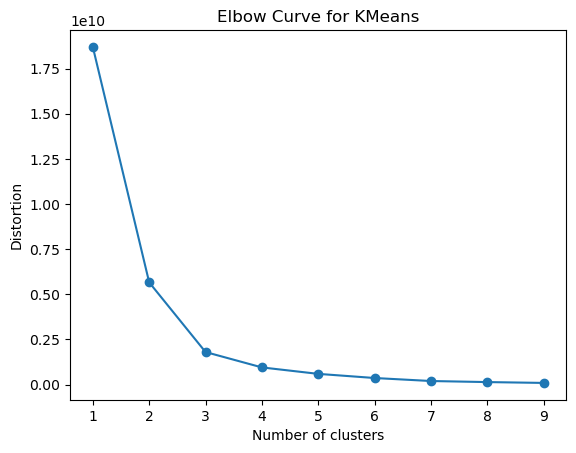

In [114]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

merged_df_encoded = merged_df_encoded.fillna(0)


distortions = []
K_range = range(1, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(merged_df_encoded)
    distortions.append(kmeans.inertia_)


plt.plot(K_range, distortions, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Distortion')
plt.title('Elbow Curve for KMeans')
plt.show()


In [115]:
n_clusters = 4
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
merged_df_encoded['cluster'] = kmeans.fit_predict(merged_df_encoded)


C:\Users\C5364375\AppData\Local\anaconda3\lib\site-packages\sklearn\cluster\_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


In [116]:
cluster_summary = merged_df_encoded.groupby('cluster').describe()

In [119]:
merged_df_encoded['cluster'].value_counts()

0    133685
3    64    
1    43    
2    11    
Name: cluster, dtype: int64

In [117]:
cluster_summary

NumberOfLegalEntities                                                                                                                name_leak                                                    Total_donation_EUR                                                                           times_donated                                                      Unique_parties_donated                                              
                        count       mean        std  min  25%   50%   75%    max     count       mean        std  min  25%   50%   75%   max     count       mean       std   min   25%   50%   75%   max              count          mean          std       min       25%      50%      75%      max         count       mean        std   min    25%   50%   75%   max                  count      mean       std  min  25%  50%   75%  max
cluster                                                                                                                                                                                                                                                                                                                                                                                                                                       
0        133685.0              1.326978   1.168174   1.0  1.0  1.0   1.0   137.0  133685.0  0.003561   0.091951   0.0  0.0  0.0   0.0   7.0   133685.0  18.993051  0.342419  0.0   19.0  19.0  19.0  19.0  133685.0           1.119147      40.360405    0.00      0.00      0.0      0.0      2600.0   133685.0      0.007226   0.296255   0.0   0.00   0.0   0.0   72.0  133685.0               0.002341  0.055533  0.0  0.0  0.0  0.00  3.0
1        43.0                  13.279070  15.816395  1.0  2.0  3.0   38.0  38.0   43.0      13.279070  15.816395  1.0  2.0  3.0   38.0  38.0  43.0      19.000000  0.000000  19.0  19.0  19.0  19.0  19.0  43.0               11843.589767  2545.050911  9400.00   10000.00  12000.0  12100.0  17330.0  43.0          8.906977   14.584424  1.0   2.00   2.0   9.0   53.0  43.0                   1.651163  0.650411  1.0  1.0  2.0  2.00  3.0
2        11.0                  5.909091   4.700097   1.0  1.0  10.0  10.0  10.0   11.0      5.909091   4.700097   1.0  1.0  10.0  10.0  10.0  11.0      19.000000  0.000000  19.0  19.0  19.0  19.0  19.0  11.0               29991.896364  5623.461887  21670.54  24830.08  34820.0  34820.0  34820.0  11.0          47.090909  18.571239  13.0  50.00  50.0  51.0  70.0  11.0                   1.181818  0.404520  1.0  1.0  1.0  1.00  2.0
3        64.0                  2.546875   1.699016   1.0  1.0  2.0   5.0   5.0    64.0      2.546875   1.699016   1.0  1.0  2.0   5.0   5.0   64.0      19.000000  0.000000  19.0  19.0  19.0  19.0  19.0  64.0               5365.041719   1497.074186  2730.00   4123.00   5420.0   6165.0   7403.1   64.0          10.234375  7.278457   1.0   5.75   9.0   16.0  36.0  64.0                   2.031250  0.815889  1.0  1.0  2.0  2.25  4.0

In [122]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=3, min_samples=2)  # You may need to adjust eps and min_samples based on your data
merged_df_encoded['cluster'] = dbscan.fit_predict(merged_df_encoded)

# Visualize clusters
plt.scatter(merged_df_encoded['feature1'], merged_df_encoded['feature2'], c=merged_df_encoded['cluster'], cmap='viridis')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('DBSCAN Clustering')
plt.show()

# Descriptive Analysis of Clusters
cluster_summary = merged_df_encoded.groupby('cluster').describe()
print(cluster_summary)

MemoryError: 